In [2]:
print("Welcome to NLP Spam-Ham Classification Project!")

Welcome to NLP Spam-Ham Classification Project!


In [3]:
import pandas as pd

In [5]:
df = pd.read_csv("../dataset/spam.csv", encoding="latin-1")
print(df.head())
print("Dataset Shape:", df.shape)
print(df.columns)

     v1                                                 v2 Unnamed: 2  \
0   ham  Go until jurong point, crazy.. Available only ...        NaN   
1   ham                      Ok lar... Joking wif u oni...        NaN   
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...        NaN   
3   ham  U dun say so early hor... U c already then say...        NaN   
4   ham  Nah I don't think he goes to usf, he lives aro...        NaN   

  Unnamed: 3 Unnamed: 4  
0        NaN        NaN  
1        NaN        NaN  
2        NaN        NaN  
3        NaN        NaN  
4        NaN        NaN  
Dataset Shape: (5572, 5)
Index(['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'], dtype='str')


In [7]:
df.info()
print(df.isnull().sum())
print(df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   v1          5572 non-null   str  
 1   v2          5572 non-null   str  
 2   Unnamed: 2  50 non-null     str  
 3   Unnamed: 3  12 non-null     str  
 4   Unnamed: 4  6 non-null      str  
dtypes: str(5)
memory usage: 679.8 KB
v1               0
v2               0
Unnamed: 2    5522
Unnamed: 3    5560
Unnamed: 4    5566
dtype: int64
403


In [8]:
df = df[['v1', 'v2']]

print(df.head())

     v1                                                 v2
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...


In [9]:
df.columns = ['label', 'message']

print(df.head())

  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...


In [10]:
df = df.drop_duplicates()

print("Dataset Shape:", df.shape)
print("Duplicate Rows:", df.duplicated().sum())

Dataset Shape: (5169, 2)
Duplicate Rows: 0


In [11]:
df['label'].value_counts()

label
ham     4516
spam     653
Name: count, dtype: int64

In [12]:
df['label'].value_counts(normalize=True) * 100

label
ham     87.366996
spam    12.633004
Name: proportion, dtype: float64

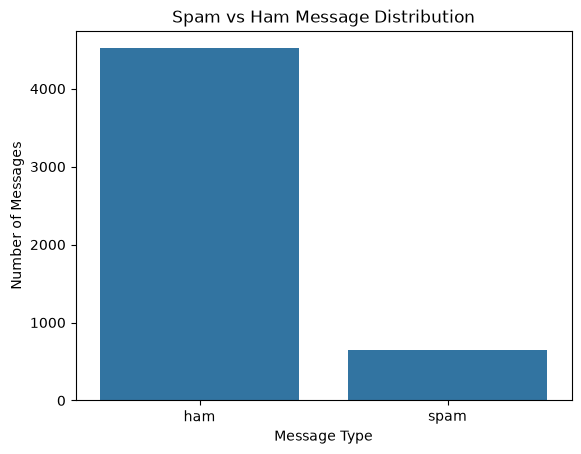

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x='label')

plt.title("Spam vs Ham Message Distribution")
plt.xlabel("Message Type")
plt.ylabel("Number of Messages")

plt.show()

In [14]:
df['message'] = df['message'].str.lower()

print(df['message'].head())

0    go until jurong point, crazy.. available only ...
1                        ok lar... joking wif u oni...
2    free entry in 2 a wkly comp to win fa cup fina...
3    u dun say so early hor... u c already then say...
4    nah i don't think he goes to usf, he lives aro...
Name: message, dtype: str


In [15]:
import string

print(string.punctuation)

!"#$%&'()*+,-./:;<=>?@[\]^_`{|}~


In [16]:
df['message'] = df['message'].apply(
    lambda text: text.translate(str.maketrans('', '', string.punctuation))
)

print(df['message'].head())

0    go until jurong point crazy available only in ...
1                              ok lar joking wif u oni
2    free entry in 2 a wkly comp to win fa cup fina...
3          u dun say so early hor u c already then say
4    nah i dont think he goes to usf he lives aroun...
Name: message, dtype: str


In [19]:
%pip install nltk

Defaulting to user installation because normal site-packages is not writeable
  Using cached nltk-3.10.4-py3-none-any.whl.metadata (5.0 kB)
Using cached nltk-3.10.4-py3-none-any.whl (1.7 MB)
Note: you may need to restart the kernel to use updated packages.


In [21]:
import nltk
nltk.download('punkt_tab')
from nltk.tokenize import word_tokenize

text = "free entry win a prize today"

tokens = word_tokenize(text)

print(tokens)

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\DELL\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt_tab.zip.


['free', 'entry', 'win', 'a', 'prize', 'today']


In [22]:
import nltk

nltk.download('stopwords')
from nltk.corpus import stopwords

stop_words = set(stopwords.words('english'))

print(stop_words)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\DELL\AppData\Roaming\nltk_data...


{'and', 't', 'on', 'here', 'm', 'your', 'until', 'but', 'very', "he'd", 'shouldn', 'hadn', 'needn', 'isn', 'only', 'was', 'both', 'we', 'our', "i'm", 'to', 'aren', 'yourselves', 'against', 'doesn', 's', "wasn't", 'weren', 'his', 'other', 'of', 'about', 'with', "they've", "aren't", 'should', "should've", "they're", 'ma', 'did', 'had', 'does', "i've", 'shan', 'too', "i'd", 'i', 'ours', 'how', "isn't", "we've", 'being', 'some', "mustn't", 'same', 'my', "that'll", 'wasn', 'don', "mightn't", 'who', 'themselves', 'or', 'any', "we're", "you'd", 'just', 'out', 'into', "we'll", 'them', 'll', 'mustn', 'then', 'do', 'while', 'were', "hadn't", 'ain', 'me', 'no', "shouldn't", 'up', 'through', 'yourself', "you've", 'be', 'her', 'theirs', 'o', "i'll", "don't", 'during', "she's", "he's", 'those', "they'd", 'where', 'under', "needn't", "it's", "won't", 'before', "you'll", 'that', 'these', 'by', 'been', 'the', 'down', 'over', 'few', 'she', 'are', "she'd", 'him', "it'd", 'doing', 'so', 'am', 'herself', '

[nltk_data]   Unzipping corpora\stopwords.zip.


In [23]:
text = "this is a free offer for you"

words = text.split()

filtered_words = [
    word for word in words
    if word not in stop_words
]

print("Original Words:", words)
print("After Stopwords Removal:", filtered_words)

Original Words: ['this', 'is', 'a', 'free', 'offer', 'for', 'you']
After Stopwords Removal: ['free', 'offer']


In [24]:
# Stopwords list
preserve_words = {'no', 'nor', 'not', 'never', 'dont', 'cant', 'cannot'}

stop_words = set(stopwords.words('english')) - preserve_words

# Stopwords removal function
def remove_stopwords(text):
    words = word_tokenize(text)

    filtered_words = [
        word for word in words
        if word not in stop_words
    ]

    return " ".join(filtered_words)

# Apply to dataset
df['message'] = df['message'].apply(remove_stopwords)

# Display results
print(df[['label', 'message']].head())

  label                                            message
0   ham  go jurong point crazy available bugis n great ...
1   ham                            ok lar joking wif u oni
2  spam  free entry 2 wkly comp win fa cup final tkts 2...
3   ham                u dun say early hor u c already say
4   ham        nah dont think goes usf lives around though


In [25]:
from nltk.stem import PorterStemmer

# Create Stemmer object
stemmer = PorterStemmer()

# Stemming function
def apply_stemming(text):
    words = word_tokenize(text)

    stemmed_words = [
        stemmer.stem(word) for word in words
    ]

    return " ".join(stemmed_words)

# Apply stemming to dataset
df['message'] = df['message'].apply(apply_stemming)

# Display results
print(df[['label', 'message']].head())

  label                                            message
0   ham  go jurong point crazi avail bugi n great world...
1   ham                              ok lar joke wif u oni
2  spam  free entri 2 wkli comp win fa cup final tkt 21...
3   ham                u dun say earli hor u c alreadi say
4   ham          nah dont think goe usf live around though


In [26]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Create TF-IDF object
tfidf = TfidfVectorizer(max_features=3000)

# Convert messages into numerical features
X = tfidf.fit_transform(df['message'])

# Target variable
y = df['label'].map({'ham': 0, 'spam': 1})

print("Feature Matrix Shape:", X.shape)
print("Target Shape:", y.shape)

Feature Matrix Shape: (5169, 3000)
Target Shape: (5169,)


In [27]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print( X_train.shape)
print( X_test.shape)

print(y_train.shape)
print( y_test.shape)

(4135, 3000)
(1034, 3000)
(4135,)
(1034,)


In [28]:
from sklearn.naive_bayes import MultinomialNB
model = MultinomialNB()
model.fit(X_train, y_train)
print("Model Training Completed Successfully!")

Model Training Completed Successfully!


In [29]:
y_pred = model.predict(X_test)
print( y_pred[:10])
print( y_test.values[:10])

[0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0]


In [30]:
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test, y_pred)
print(accuracy * 100, "%")

97.678916827853 %


In [31]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=['Ham', 'Spam']
))

              precision    recall  f1-score   support

         Ham       0.98      1.00      0.99       903
        Spam       0.99      0.82      0.90       131

    accuracy                           0.98      1034
   macro avg       0.98      0.91      0.94      1034
weighted avg       0.98      0.98      0.98      1034



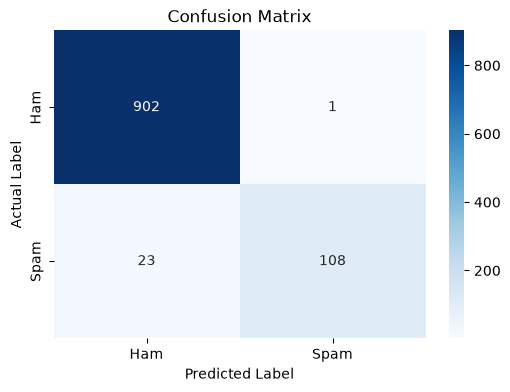

In [32]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Ham', 'Spam'],
    yticklabels=['Ham', 'Spam']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Confusion Matrix')

plt.show()

In [34]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight='balanced'
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
print("Random Forest Accuracy:",
      accuracy_score(y_test, rf_pred) * 100)

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_pred,
    target_names=['Ham', 'Spam']
))

Random Forest Accuracy: 98.16247582205028

Classification Report:
              precision    recall  f1-score   support

         Ham       0.98      1.00      0.99       903
        Spam       0.97      0.89      0.92       131

    accuracy                           0.98      1034
   macro avg       0.98      0.94      0.96      1034
weighted avg       0.98      0.98      0.98      1034



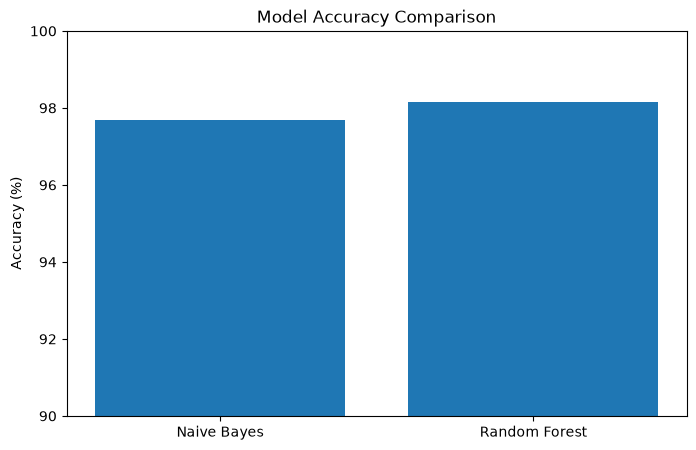

           Model   Accuracy
0    Naive Bayes  97.678917
1  Random Forest  98.162476


In [35]:
import pandas as pd
import matplotlib.pyplot as plt

comparison = pd.DataFrame({
    'Model': ['Naive Bayes', 'Random Forest'],
    'Accuracy': [
        accuracy_score(y_test, y_pred) * 100,
        accuracy_score(y_test, rf_pred) * 100
    ]
})

plt.figure(figsize=(8, 5))

plt.bar(comparison['Model'], comparison['Accuracy'])

plt.ylabel('Accuracy (%)')
plt.title('Model Accuracy Comparison')
plt.ylim(90, 100)

plt.show()

print(comparison)

In [36]:
import os
import pickle
os.makedirs("../models", exist_ok=True)
with open("../models/spam_ham_model.pkl", "wb") as file:
    pickle.dump(rf_model, file)
with open("../models/tfidf_vectorizer.pkl", "wb") as file:
    pickle.dump(tfidf, file)

print("Model Saved Successfully!")
print("TF-IDF Vectorizer Saved Successfully!")

Model Saved Successfully!
TF-IDF Vectorizer Saved Successfully!


In [37]:
import pickle
with open("../models/spam_ham_model.pkl", "rb") as file:
    loaded_model = pickle.load(file)
with open("../models/tfidf_vectorizer.pkl", "rb") as file:
    loaded_tfidf = pickle.load(file)
new_message = ["Congratulations! You won a free prize. Claim now"]
message_vector = loaded_tfidf.transform(new_message)
prediction = loaded_model.predict(message_vector)

if prediction[0] == 1:
    print("Prediction: SPAM")
else:
    print("Prediction: HAM")

Prediction: SPAM


In [38]:
test_messages = [
    "Congratulations! You won a free prize. Claim now",
    "Hey, are you coming to college today?",
    "URGENT! You have won 1000 pounds. Call now"
]

message_vectors = loaded_tfidf.transform(test_messages)

predictions = loaded_model.predict(message_vectors)

for message, prediction in zip(test_messages, predictions):

    result = "SPAM" if prediction == 1 else "HAM"

    print("Message:", message)
    print("Prediction:", result)
    print("-" * 50)

Message: Congratulations! You won a free prize. Claim now
Prediction: SPAM
--------------------------------------------------
Message: Hey, are you coming to college today?
Prediction: HAM
--------------------------------------------------
Message: URGENT! You have won 1000 pounds. Call now
Prediction: SPAM
--------------------------------------------------
